<h1 style="text-align:center; color:#245A81;">
    SOCIAL MEDIA ENGAGEMENT ANALYTICS
</h1>
<hr style="border:2px solid #3986DB;">
<p style="text-align:center; color:gray;">
    Python for Data Analysis 
</p>


<div style="
    background: #EAF3FC;
    padding: 14px 20px;
    border-left: 5px solid #2878B8;
    border-radius: 5px;
">
    <h2 style="color: #174B75; margin: 0;">
        01 | PROJECT INTRODUCTION
    </h2>
</div>



### 1.1 Problem Statement

Social media platforms generate large volumes of engagement data,
including likes, comments, shares, impressions and watch time.

Analyzing these metrics helps organizations understand audience
behavior, evaluate content effectiveness and identify opportunities
to improve their social media strategies.

### 1.2 Project Objectives

- Analyze social media engagement metrics.
- Identify high-performing post types and content categories.
- Examine audience demographics and engagement patterns.
- Understand the relationship between impressions and engagement.
- Evaluate sentiment and device-based engagement.
- Develop actionable, data-driven business recommendations.

### 1.3 Analytical Approach

This project follows a structured data analytics workflow:

Data Collection → Data Cleaning → Data Transformation →
Exploratory Analysis → Statistical Analysis →
Data Visualization → Business Insights.


In [168]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [169]:
# Loading the dataset
url = "https://raw.githubusercontent.com/GeethaGunasekaran1/Dataset_rep/main/social_media_engagement_5000.csv"
df = pd.read_csv(url)

<div style="
    background: #EAF3FC;
    padding: 14px 20px;
    border-left: 5px solid #2878B8;
    border-radius: 5px;
">
    <h2 style="color: #174B75; margin: 0;">
        02 | DATA UNDERSTANDING & EXPLORATION
    </h2>
</div>


In [170]:
# Check the number of rows and columns
df.shape

(5000, 19)

In [171]:
# Display the first five records
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [172]:
# Display the last five records
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518
4999,73400,54.0,Other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,04-03-2023,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527


In [173]:
# Display all column names
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='str')

In [174]:
# Display dataset structure and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   str    
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   str    
 16  sentiment         4850 non-null   str    
 17  hashta

In [175]:
# Generate descriptive statistics
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate
count,5000.000000,4850.000000,5000.000000,4850.000000,4850.000000,4850.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.454021,548042.909000,10107.043711,1502.195670,1002.629485,4014.503200,50013.732800,393698.224800,0.964356
std,26090.370121,14.912381,260646.957267,5789.819252,869.537889,579.615158,2308.096459,28844.939104,230927.884535,5.318029
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.000000,0.000000,105.000000,87.000000,0.006363
25%,32309.500000,26.000000,322543.500000,5068.500000,760.000000,498.000000,2017.750000,24988.250000,194480.000000,0.145781
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.000000,4034.500000,49934.500000,388982.000000,0.253896
75%,77180.500000,51.000000,771574.500000,15115.000000,2256.000000,1501.000000,6020.250000,74662.250000,589744.250000,0.504794
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.000000,7998.000000,99995.000000,799533.000000,191.504348


In [176]:
# Using NumPy arrays for basic array operations

In [177]:
# Convert Pandas columns into NumPy arrays
likes_array = df['likes'].to_numpy()
comments_array = df['comments'].to_numpy()

In [178]:
# Calculate total engagement
total_engagement = likes_array + comments_array
print(total_engagement[:10])

[ 7365. 14356.  5206.  6433. 15417. 14325. 13979.  9757.    nan 16586.]


In [179]:
#Calculate average likes
print(np.nanmean(likes_array))

10107.043711340206


In [180]:
#Find maximum and minimum likes
print("Maximum Likes:", np.nanmax(likes_array))
print("Minimum Likes:", np.nanmin(likes_array))

Maximum Likes: 19998.0
Minimum Likes: 10.0


<div style="
    background: #EAF3FC;
    padding: 14px 20px;
    border-left: 5px solid #2878B8;
    border-radius: 5px;
">
    <h2 style="color: #174B75; margin: 0;">
        03 | DATA CLEANING & PREPROCESSING
    </h2>
</div>

In [181]:
# Convert posted_at column into datetime format
df['posted_at'] = pd.to_datetime(df['posted_at'])
print(df['posted_at'].dtype)

datetime64[us]


C:\Users\DELL\AppData\Local\Temp\ipykernel_13152\1673816196.py:2: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['posted_at'] = pd.to_datetime(df['posted_at'])


In [182]:
# Count missing values in each column
df.isnull().sum()

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

In [183]:
# Calculate missing value percentages
(df.isnull().sum()/len(df))*100

user_id             0.0
age                 3.0
gender              3.0
country             0.0
post_id             0.0
post_type           0.0
post_category       0.0
likes               3.0
comments            3.0
shares              3.0
watch_time_sec      0.0
impression_count    0.0
posted_at           0.0
follower_count      0.0
is_verified         0.0
device_type         0.0
sentiment           3.0
hashtags            0.0
engagement_rate     0.0
dtype: float64

In [184]:
# Fill missing numerical values with median
num_cols = ['age', 'likes', 'comments', 'shares']
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

In [185]:
df[num_cols].isnull().sum()

age         0
likes       0
comments    0
shares      0
dtype: int64

In [186]:
## Fill missing Categorical missing values with mode
cat_cols = ['gender', 'sentiment']
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [187]:
df.isnull().sum()

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64

In [188]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()
print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


In [189]:
# Change data type to int
int_cols = ['age', 'likes', 'comments', 'shares']
df[int_cols] = df[int_cols].astype(int)
df[int_cols].dtypes

age         int64
likes       int64
comments    int64
shares      int64
dtype: object

In [190]:
cat_cols = ['gender', 'country', 'post_type', 'post_category', 'device_type', 'sentiment']
for col in cat_cols:
    print(df[col].value_counts())

gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64
country
India        535
Canada       513
Brazil       504
UAE          503
USA          501
France       496
UK           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: int64
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64
post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       600
fashion      594
food         593
Name: count, dtype: int64
device_type
mobile     1684
tablet     1658
desktop    1658
Name: count, dtype: int64
sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64


In [191]:
# Standardize categories
for col in cat_cols:
    df[col] = df[col].str.strip().str.title()
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43,Female,Brazil,496713,Image,Fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,Mobile,Negative,#foodie #travel #love,0.190862
1,10860,33,Male,Brazil,157326,Reel,Food,11750,2606,1807,5947,80216,2023-06-02,5963,False,Mobile,Negative,#fitness,0.201493
2,86820,32,Female,Uk,109864,Text,Food,4862,344,955,6946,44858,2023-05-07,501783,False,Tablet,Positive,#foodie,0.137345
3,64886,51,Other,France,848877,Text,Fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,Mobile,Negative,#music #foodie #fun,0.106195
4,16265,34,Other,Uk,449706,Image,Fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,Mobile,Negative,#travel,2.777372


In [192]:
# checking negative values
num_check_cols = [
    'likes', 'comments', 'shares',
    'watch_time_sec', 'impression_count',
    'follower_count', 'engagement_rate'
]

for col in num_check_cols:
    print(col, ":", (df[col] < 0).sum())

likes : 0
comments : 0
shares : 0
watch_time_sec : 0
impression_count : 0
follower_count : 0
engagement_rate : 0


In [193]:
# check whether impression is more than likes comments or shares
print("Likes greater than impressions:", 
      (df['likes'] > df['impression_count']).sum())

print("Comments greater than impressions:", 
      (df['comments'] > df['impression_count']).sum())

print("Shares greater than impressions:", 
      (df['shares'] > df['impression_count']).sum())

Likes greater than impressions: 464
Comments greater than impressions: 65
Shares greater than impressions: 55


In [194]:
df[['likes', 'comments', 'shares', 'impression_count']].describe()

,likes,comments,shares,impression_count
count,5000.000000,5000.000000,5000.0000,5000.000000
mean,10106.982400,1502.039800,1002.9106,50013.732800
std,5702.293022,856.393312,570.8552,28844.939104
min,10.000000,0.000000,0.0000,105.000000
25%,5235.000000,792.000000,511.0000,24988.250000
50%,10105.000000,1497.000000,1012.0000,49934.500000
75%,14959.000000,2235.250000,1483.0000,74662.250000
max,19998.000000,2999.000000,1999.0000,99995.000000


In [195]:
# outlier detection
engagement_cols = ['likes', 'comments', 'shares']

for col in engagement_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_limit) | (df[col] > upper_limit)]

    print(f"\n{col}")
    print("Lower limit:", lower_limit)
    print("Upper limit:", upper_limit)
    print("Number of outliers:", len(outliers))


likes
Lower limit: -9351.0
Upper limit: 29545.0
Number of outliers: 0

comments
Lower limit: -1372.875
Upper limit: 4400.125
Number of outliers: 0

shares
Lower limit: -947.0
Upper limit: 2941.0
Number of outliers: 0


In [196]:
# Extract hashtag count
df['hashtag_count'] = df['hashtags'].str.count('#')
df[['hashtags', 'hashtag_count']].head(10)

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1
5,#fitness,1
6,#music,1
7,#travel #music #fitness,3
8,#music #fun #fitness,3
9,#lifestyle #love,2


In [197]:
df['sentiment'].unique()

<ArrowStringArray>
['Negative', 'Positive', 'Neutral']
Length: 3, dtype: str

In [198]:
df['sentiment'].value_counts()

sentiment
Positive    2513
Neutral     1527
Negative     960
Name: count, dtype: int64

In [199]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (5000, 20)

Missing Values:
user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
hashtag_count       0
dtype: int64

Duplicate Records: 0

Data Types:
user_id                      int64
age                          int64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                        int64
comments                     int64
shares                       int64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count

<div style="
    background: #EAF3FC;
    padding: 14px 20px;
    border-left: 5px solid #2878B8;
    border-radius: 5px;
">
    <h2 style="color: #174B75; margin: 0;">
        04 | Exploratory Data Analysis (EDA)
    </h2>
</div>

In [200]:
print("First 5 Records:")
display(df.head())

print("\nLast 5 Records:")
display(df.tail())

print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

First 5 Records:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43,Female,Brazil,496713,Image,Fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,Mobile,Negative,#foodie #travel #love,0.190862,3
1,10860,33,Male,Brazil,157326,Reel,Food,11750,2606,1807,5947,80216,2023-06-02,5963,False,Mobile,Negative,#fitness,0.201493,1
2,86820,32,Female,Uk,109864,Text,Food,4862,344,955,6946,44858,2023-05-07,501783,False,Tablet,Positive,#foodie,0.137345,1
3,64886,51,Other,France,848877,Text,Fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,Mobile,Negative,#music #foodie #fun,0.106195,3
4,16265,34,Other,Uk,449706,Image,Fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,Mobile,Negative,#travel,2.777372,1



Last 5 Records:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44,Male,Australia,441541,Video,Education,16210,2013,1837,6190,42977,2022-06-25,646147,False,Mobile,Positive,#travel #fun,0.466761,2
4996,22100,38,Other,Uae,677076,Reel,Education,16924,2734,1583,7764,34196,2022-11-18,584603,False,Desktop,Negative,#foodie #reels,0.621155,2
4997,67021,63,Female,Usa,273595,Text,Travel,13487,1497,167,7466,23680,2023-04-06,483550,False,Desktop,Positive,#lifestyle #tech,0.679688,2
4998,29800,13,Female,Germany,785644,Video,Fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,Tablet,Positive,#reels #love #fitness,0.223518,3
4999,73400,54,Other,Japan,712252,Text,Travel,14830,503,1798,3743,14234,2023-03-04,585760,False,Desktop,Neutral,#foodie #lifestyle #fashion,1.203527,3



Dataset Shape: (5000, 20)

Column Names:
['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'hashtag_count']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   int64         
 2   gender            5000 non-null   str           
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             5000 non-null   int64         
 8   comments          5000 

In [201]:
# Descriptive statistics
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.982400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.000000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293022,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


In [202]:
#Analyze categorical distributions

In [203]:
cat_cols = ['gender', 'country', 'post_type',
            'post_category', 'device_type', 'sentiment']
for col in cat_cols:
    print(df[col].value_counts())

gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64
country
India        535
Canada       513
Brazil       504
Uae          503
Usa          501
France       496
Uk           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: int64
post_type
Reel     1283
Image    1247
Text     1245
Video    1225
Name: count, dtype: int64
post_category
Fitness      675
Tech         665
Music        635
Education    631
Lifestyle    607
Travel       600
Fashion      594
Food         593
Name: count, dtype: int64
device_type
Mobile     1684
Tablet     1658
Desktop    1658
Name: count, dtype: int64
sentiment
Positive    2513
Neutral     1527
Negative     960
Name: count, dtype: int64


In [204]:
for col in cat_cols:
    print(df[col].unique())

<ArrowStringArray>
['Female', 'Male', 'Other']
Length: 3, dtype: str
<ArrowStringArray>
[   'Brazil',        'Uk',    'France',    'Canada',     'Japan', 'Australia',
     'India',       'Uae',   'Germany',       'Usa']
Length: 10, dtype: str
<ArrowStringArray>
['Image', 'Reel', 'Text', 'Video']
Length: 4, dtype: str
<ArrowStringArray>
[  'Fitness',      'Food',      'Tech',    'Travel',   'Fashion', 'Lifestyle',
 'Education',     'Music']
Length: 8, dtype: str
<ArrowStringArray>
['Mobile', 'Tablet', 'Desktop']
Length: 3, dtype: str
<ArrowStringArray>
['Negative', 'Positive', 'Neutral']
Length: 3, dtype: str


In [205]:
for col in cat_cols:
    print(col,":",df[col].nunique())

gender : 3
country : 10
post_type : 4
post_category : 8
device_type : 3
sentiment : 3


In [206]:
#correlation matrix for numeric fields
numeric_df = df.select_dtypes(include='number')
correlation_matrix = numeric_df.corr()
correlation_matrix

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282,-0.013692
age,-0.006688,1.000000,-0.013153,-0.036323,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,0.007173
post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139,0.007344
likes,0.025811,-0.036323,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,0.093521,-0.002190
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,-0.015230
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,0.013379
watch_time_sec,-0.016847,0.005542,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,-0.023301
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,-0.002714
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,0.008802
engagement_rate,-0.004282,0.008039,0.010139,0.093521,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,0.005319


In [207]:
# Average engagement by post type
df.groupby('post_type')['engagement_rate'].mean().sort_values(ascending=False)

post_type
Video    1.122365
Text     1.064549
Image    0.895646
Reel     0.783047
Name: engagement_rate, dtype: float64

In [208]:
# Average likes by post type
df.groupby('post_type')['likes'].mean().sort_values(ascending=False).round(2)


post_type
Video    10188.59
Image    10104.85
Text     10100.13
Reel     10037.78
Name: likes, dtype: float64

In [209]:
# Total impressions by country
df.groupby('country')['impression_count'].sum().sort_values(ascending=False)

country
India        28067377
Usa          25683200
France       25656926
Uk           25201861
Canada       24984716
Brazil       24793360
Uae          24610992
Australia    23834767
Germany      23816649
Japan        23418816
Name: impression_count, dtype: int64

In [210]:
# Average engagement by device type
df.groupby('device_type')['engagement_rate'].mean().sort_values(ascending=False)

device_type
Mobile     1.123999
Desktop    0.962006
Tablet     0.804560
Name: engagement_rate, dtype: float64

In [211]:
# Verified vs unverified users
df.groupby('is_verified')['engagement_rate'].mean().round(2)

is_verified
False    0.95
True     1.05
Name: engagement_rate, dtype: float64

In [212]:
#Average likes and impressions by country
df.groupby('country').agg({
    'likes': 'mean',
    'impression_count': 'mean'
}).round(2)

,likes,impression_count
country,,
Australia,10294.11,48346.38
Brazil,9886.68,49193.17
Canada,10063.05,48703.15
France,10372.86,51727.67
Germany,10130.43,48605.41
India,9962.44,52462.39
Japan,10088.85,49616.14
Uae,10227.47,48928.41
Uk,9935.64,51119.39


In [213]:
# Average followers by sentiment
df.groupby('sentiment')['follower_count'].mean().sort_values(ascending=False).round(2)

sentiment
Negative    397430.43
Positive    394174.25
Neutral     390568.45
Name: follower_count, dtype: float64

In [214]:
# Average engagement rate by gender
df.groupby('gender')['engagement_rate'].mean().sort_values(ascending=False).round(2)

gender
Male      1.06
Other     0.91
Female    0.91
Name: engagement_rate, dtype: float64

In [215]:
#Average comments by post type
df.groupby('post_type')['comments'].mean().sort_values(ascending=False).round(2)

post_type
Image    1525.24
Reel     1504.19
Text     1499.11
Video    1479.16
Name: comments, dtype: float64

In [216]:
# Multiple engagement metrics by post category
df.groupby('post_category').agg({'likes': 'mean','comments': 'mean','shares': 'mean','engagement_rate': 'mean'}).round(2)

,likes,comments,shares,engagement_rate
post_category,,,,
Education,10126.47,1455.34,996.45,0.84
Fashion,9843.34,1530.54,982.52,0.81
Fitness,9914.59,1501.14,1042.05,0.87
Food,10225.50,1510.88,1002.80,1.36
Lifestyle,10180.54,1467.84,991.14,1.09
Music,10205.74,1558.71,1024.09,0.89
Tech,10171.56,1505.55,1009.37,1.16
Travel,10196.29,1485.95,968.31,0.70


<div style="
    background: #EAF3FC;
    padding: 14px 20px;
    border-left: 5px solid #2878B8;
    border-radius: 5px;
">
    <h2 style="color: #174B75; margin: 0;">
        05 | Data Wrangling and Feature Engineering
    </h2>
</div>

In [217]:
# Create Engagement Score
df['engagement_score'] = (
    df['likes'] + df['comments'] + df['shares']
)

In [218]:
df[['likes', 'comments', 'shares', 'engagement_score']].head(10)

,likes,comments,shares,engagement_score
0,7011,354,1157,8522
1,11750,2606,1807,16163
2,4862,344,955,6161
3,5350,1083,1049,7482
4,12682,2735,1300,16717
5,12535,1790,99,14424
6,11703,2276,1465,15444
7,9611,146,424,10181
8,10105,2379,1897,14381
9,14106,2480,1053,17639


In [219]:
# Extract posting date and time features
df['post_date'] = df['posted_at'].dt.date

df['post_day'] = df['posted_at'].dt.day_name()

df['post_month'] = df['posted_at'].dt.month_name()

In [220]:
df[['posted_at', 'post_date', 'post_day', 'post_month']].head(10)

,posted_at,post_date,post_day,post_month
0,2022-12-17,2022-12-17,Saturday,December
1,2023-06-02,2023-06-02,Friday,June
2,2023-05-07,2023-05-07,Sunday,May
3,2023-02-12,2023-02-12,Sunday,February
4,2023-05-23,2023-05-23,Tuesday,May
5,2023-09-16,2023-09-16,Saturday,September
6,2022-04-15,2022-04-15,Friday,April
7,2023-12-20,2023-12-20,Wednesday,December
8,2023-07-06,2023-07-06,Thursday,July
9,2022-11-16,2022-11-16,Wednesday,November


In [221]:
#Log-transform engagement metrics
log_cols = ['likes', 'comments', 'shares', 'impression_count']
for col in log_cols:
    df[f'log_{col}'] = np.log1p(df[col])
df[['likes', 'log_likes',
    'comments', 'log_comments',
    'shares', 'log_shares',
    'impression_count', 'log_impression_count']].head(10)

,likes,log_likes,comments,log_comments,shares,log_shares,impression_count,log_impression_count
0,7011,8.855378,354,5.872118,1157,7.054450,44650,10.706632
1,11750,9.371694,2606,7.865955,1807,7.499977,80216,11.292491
2,4862,8.489411,344,5.843544,955,6.862758,44858,10.711280
3,5350,8.585039,1083,6.988413,1049,6.956545,70455,11.162744
4,12682,9.448018,2735,7.914252,1300,7.170888,6019,8.702843
5,12535,9.436360,1790,7.490529,99,4.605170,24893,10.122382
6,11703,9.367686,2276,7.730614,1465,7.290293,96327,11.475514
7,9611,9.170768,146,4.990433,424,6.052089,68446,11.133815
8,10105,9.220885,2379,7.774856,1897,7.548556,36283,10.499132
9,14106,9.554426,2480,7.816417,1053,6.960348,87972,11.384785


In [222]:
df[['hashtags', 'hashtag_count']].head(10)

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1
5,#fitness,1
6,#music,1
7,#travel #music #fitness,3
8,#music #fun #fitness,3
9,#lifestyle #love,2


In [223]:
# GroupBy summary by post type
df.groupby('post_type').agg({
    'engagement_score': 'mean',
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'impression_count': 'sum'
}).round(2)

,engagement_score,likes,comments,shares,impression_count
post_type,,,,,
Image,12649.38,10104.85,1525.24,1019.29,62010095
Reel,12524.01,10037.78,1504.19,982.04,64743514
Text,12613.23,10100.13,1499.11,1013.99,62234087
Video,12664.58,10188.59,1479.16,996.83,61080968


In [224]:
# GroupBy summary by country
df.groupby('country').agg({
    'engagement_score': 'mean',
    'engagement_rate': 'mean',
    'impression_count': 'sum'
}).round(2)

,engagement_score,engagement_rate,impression_count
country,,,
Australia,12809.60,1.32,23834767
Brazil,12385.97,1.54,24793360
Canada,12605.88,0.92,24984716
France,12903.37,1.15,25656926
Germany,12635.64,0.76,23816649
India,12492.68,0.66,28067377
Japan,12578.64,0.77,23418816
Uae,12757.76,1.11,24610992
Uk,12384.36,0.85,25201861


In [225]:
# GroupBy summary by sentiment
df.groupby('sentiment').agg({
    'engagement_score': 'mean',
    'engagement_rate': 'mean',
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean'
}).round(2)

,engagement_score,engagement_rate,likes,comments,shares
sentiment,,,,,
Negative,12731.48,1.04,10208.08,1516.09,1007.31
Neutral,12448.15,0.99,9923.18,1528.40,996.57
Positive,12665.78,0.92,10180.05,1480.65,1005.09


In [226]:
#compares average engagement scores across post types and sentiments
pd.pivot_table(
    df,
    values='engagement_score',
    index='post_type',
    columns='sentiment',
    aggfunc='mean'
).round(2)

sentiment,Negative,Neutral,Positive
post_type,,,
Image,12436.72,12444.37,12847.09
Reel,13152.08,12469.16,12307.02
Text,12514.91,12421.30,12774.79
Video,12765.76,12459.33,12741.30


<div style="
    background: #EAF3FC;
    padding: 14px 20px;
    border-left: 5px solid #2878B8;
    border-radius: 5px;
">
    <h2 style="color: #174B75; margin: 0;">
        06 | Statistical Analysis
    </h2>
</div>

In [227]:
stats_cols = ['likes','comments','shares','watch_time_sec','impression_count','engagement_rate','follower_count','engagement_score']

In [228]:
# Calculate mean, median and mode
print("MEAN:")
print(df[stats_cols].mean())

print("\nMEDIAN:")
print(df[stats_cols].median())

print("\nMODE:")
print(df[stats_cols].mode().iloc[0])

MEAN:
likes                10106.982400
comments              1502.039800
shares                1002.910600
watch_time_sec        4014.503200
impression_count     50013.732800
engagement_rate          0.964356
follower_count      393698.224800
engagement_score     12611.932800
dtype: float64

MEDIAN:
likes                10105.000000
comments              1497.000000
shares                1012.000000
watch_time_sec        4034.500000
impression_count     49934.500000
engagement_rate          0.253896
follower_count      388982.000000
engagement_score     12551.500000
dtype: float64

MODE:
likes                10105.000000
comments              1497.000000
shares                1012.000000
watch_time_sec         916.000000
impression_count     24207.000000
engagement_rate          0.006363
follower_count      497502.000000
engagement_score     21623.000000
Name: 0, dtype: float64


In [229]:
# Calculate standard deviation and variance
print("STANDARD DEVIATION:")
print(df[stats_cols].std())

print("\nVARIANCE:")
print(df[stats_cols].var())

STANDARD DEVIATION:
likes                 5702.293022
comments               856.393312
shares                 570.855200
watch_time_sec        2308.096459
impression_count     28844.939104
engagement_rate          5.318029
follower_count      230927.884535
engagement_score      5782.058412
dtype: float64

VARIANCE:
likes               3.251615e+07
comments            7.334095e+05
shares              3.258757e+05
watch_time_sec      5.327309e+06
impression_count    8.320305e+08
engagement_rate     2.828143e+01
follower_count      5.332769e+10
engagement_score    3.343220e+07
dtype: float64


In [230]:
# Percentiles
print("PERCENTILES:")
print(df[stats_cols].quantile([0.25, 0.50, 0.75, 0.90, 0.95]))

PERCENTILES:
         likes  comments   shares  watch_time_sec  impression_count  \
0.25   5235.00    792.00   511.00         2017.75          24988.25   
0.50  10105.00   1497.00  1012.00         4034.50          49934.50   
0.75  14959.00   2235.25  1483.00         6020.25          74662.25   
0.90  18016.30   2695.10  1795.10         7212.10          90554.20   
0.95  19097.05   2861.00  1901.05         7577.05          94994.35   

      engagement_rate  follower_count  engagement_score  
0.25         0.145781       194480.00           7807.00  
0.50         0.253896       388982.00          12551.50  
0.75         0.504794       589744.25          17478.25  
0.90         1.201200       717755.90          20576.10  
0.95         2.328526       760174.35          21675.00  


<div style="
    background: #EAF3FC;
    padding: 14px 20px;
    border-left: 5px solid #2878B8;
    border-radius: 5px;
">
    <h2 style="color: #174B75; margin: 0;">
        07 | Data Visualization
    </h2>
</div>

**MATPLOLIB**

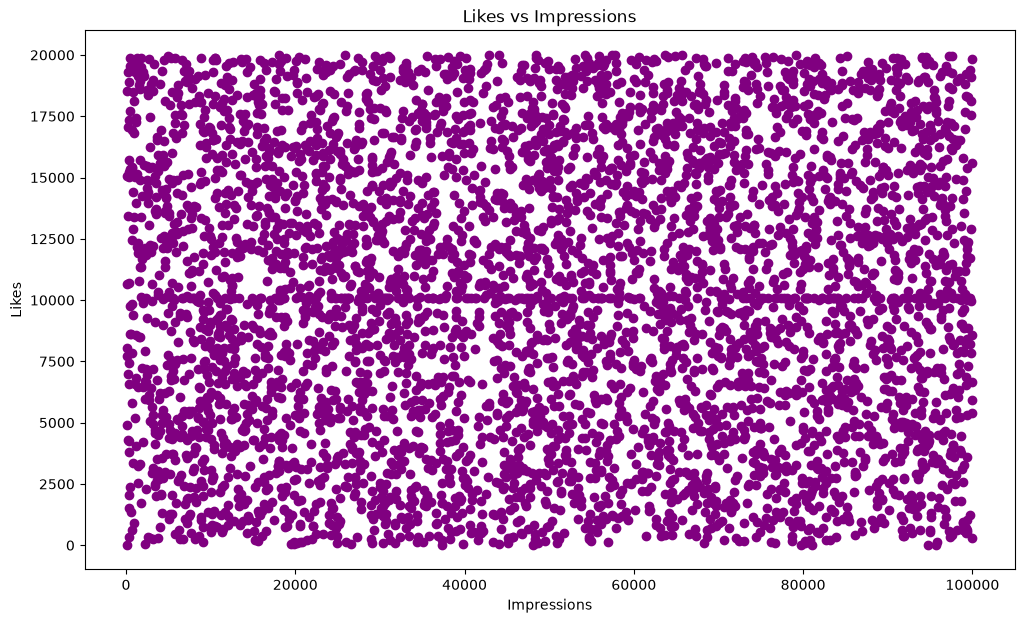

In [231]:
#Chart 1: Scatter Plot — Likes vs Impressions
plt.figure(figsize=(12, 7))
plt.scatter(df['impression_count'],df['likes'],color='purple')
plt.xlabel('Impressions')
plt.ylabel('Likes')
plt.title('Likes vs Impressions')
plt.show()

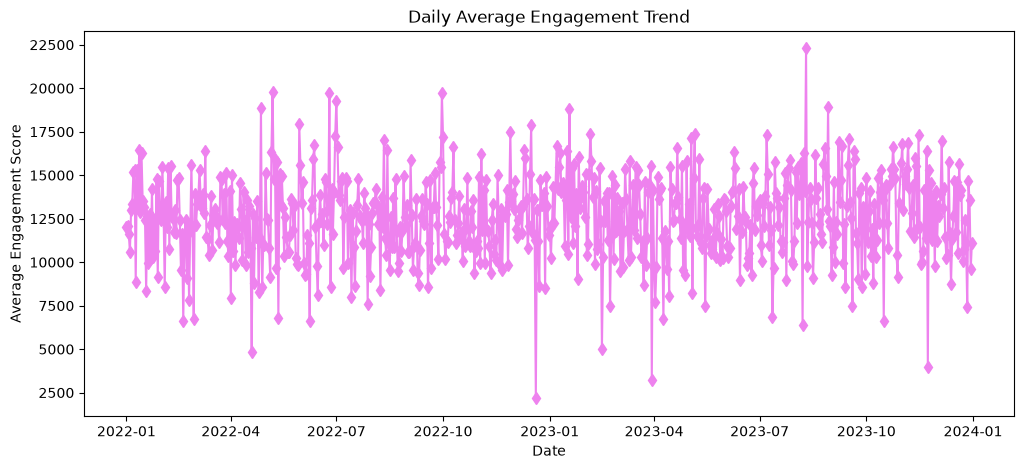

In [232]:
# Chart 2: Line Plot — Daily Engagement Trend
daily_engagement = df.groupby('post_date')['engagement_score'].mean()
plt.figure(figsize=(12, 5))
plt.plot(daily_engagement.index,daily_engagement.values,marker='d',color='violet')
plt.xlabel('Date')
plt.ylabel('Average Engagement Score')
plt.title('Daily Average Engagement Trend')
plt.show()

In [233]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,engagement_rate,hashtag_count,engagement_score,post_date,post_day,post_month,log_likes,log_comments,log_shares,log_impression_count
0,25795,43,Female,Brazil,496713,Image,Fitness,7011,354,1157,...,0.190862,3,8522,2022-12-17,Saturday,December,8.855378,5.872118,7.054450,10.706632
1,10860,33,Male,Brazil,157326,Reel,Food,11750,2606,1807,...,0.201493,1,16163,2023-06-02,Friday,June,9.371694,7.865955,7.499977,11.292491
2,86820,32,Female,Uk,109864,Text,Food,4862,344,955,...,0.137345,1,6161,2023-05-07,Sunday,May,8.489411,5.843544,6.862758,10.711280
3,64886,51,Other,France,848877,Text,Fitness,5350,1083,1049,...,0.106195,3,7482,2023-02-12,Sunday,February,8.585039,6.988413,6.956545,11.162744
4,16265,34,Other,Uk,449706,Image,Fitness,12682,2735,1300,...,2.777372,1,16717,2023-05-23,Tuesday,May,9.448018,7.914252,7.170888,8.702843


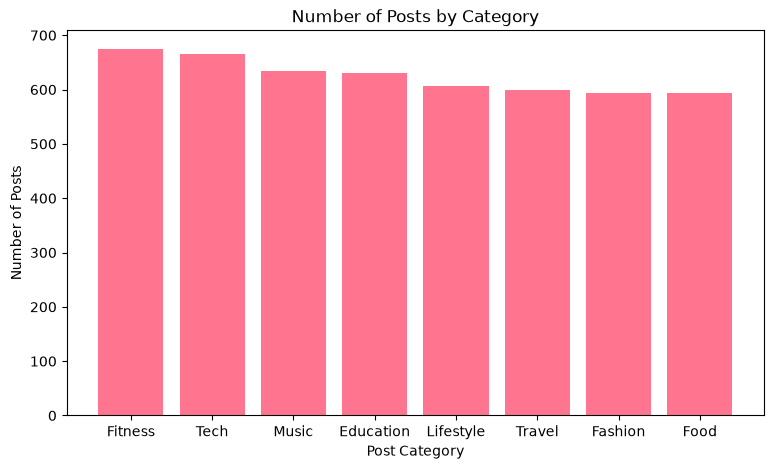

In [234]:
# Bar Chart – Number of Posts by Category
x = df['post_category'].value_counts().index
y = df['post_category'].value_counts().values
plt.figure(figsize=(9, 5))
plt.bar(x, y,color= '#ff758f')
plt.xlabel('Post Category')
plt.ylabel('Number of Posts')
plt.title('Number of Posts by Category')
plt.show()

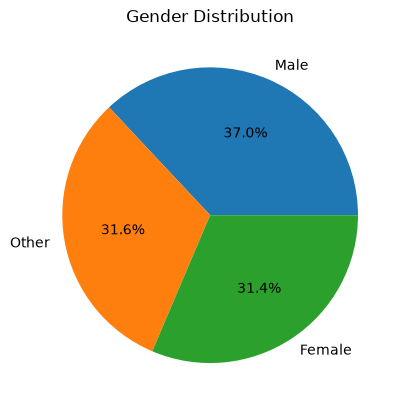

In [235]:
labels = df['gender'].value_counts().index
values = df['gender'].value_counts().values
plt.pie(values,labels=labels,autopct='%1.1f%%',)
plt.title('Gender Distribution')
plt.ylabel('')
plt.show()

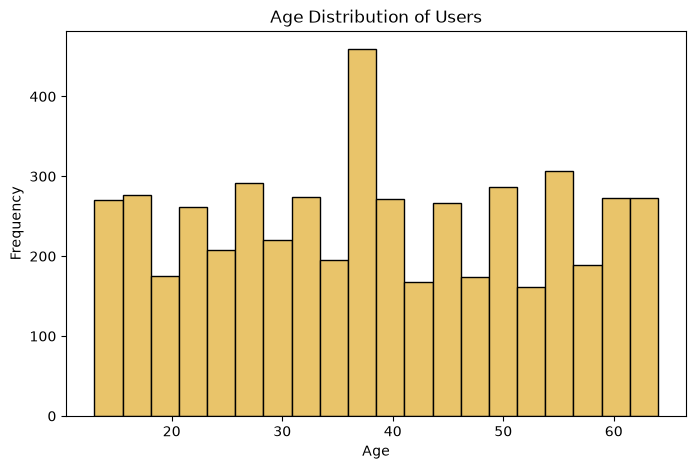

In [236]:
# Chart 5: Histogram – Age Distribution
plt.figure(figsize=(8, 5))
plt.hist(df['age'], bins=20, edgecolor='black',color='#e9c46a')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution of Users')
plt.show()

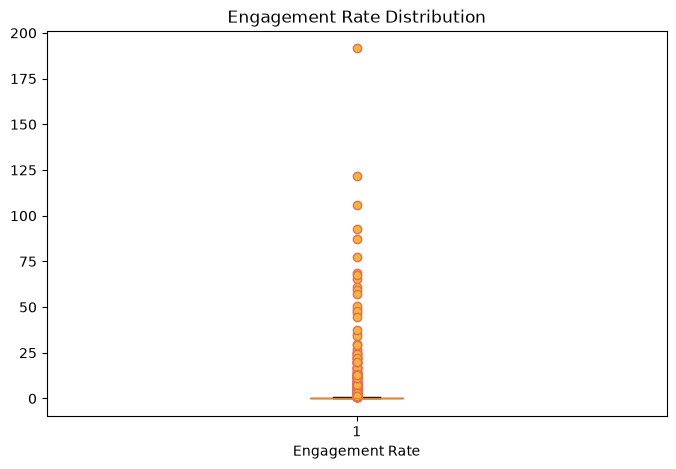

In [237]:
# Chart 6: Box Plot – Engagement Rate Distribution
plt.figure(figsize=(8, 5))
plt.boxplot(x=df['engagement_rate'],patch_artist=True,boxprops=dict(facecolor='#84a98c'),
            flierprops=dict(marker='o',markerfacecolor='#f7b538',
            markeredgecolor='#e76f51',markersize=6))
plt.xlabel('Engagement Rate')
plt.title('Engagement Rate Distribution')
plt.show()

**Seaborn**

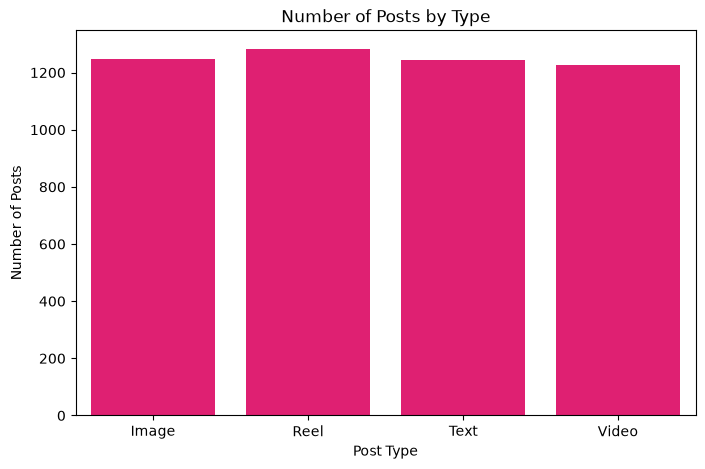

In [238]:
# Chart 7:Seaborn Count Plot – Posts by Type
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='post_type',color='#ff006e')
plt.xlabel('Post Type')
plt.ylabel('Number of Posts')
plt.title('Number of Posts by Type')
plt.show()

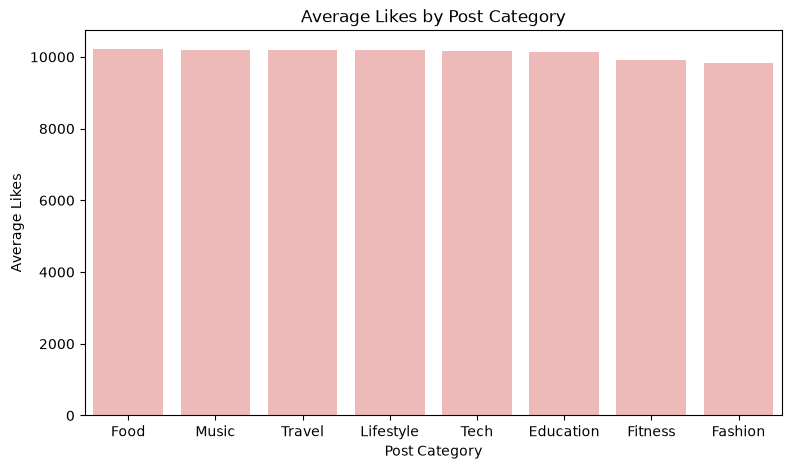

In [239]:
# Chart 8: Bar Plot – Average Likes by Post Category
avg_likes = df.groupby('post_category')['likes'].mean().sort_values(ascending=False)
plt.figure(figsize=(9, 5))
sns.barplot(x=avg_likes.index, y=avg_likes.values,color='#f7b1b0')
plt.xlabel('Post Category')
plt.ylabel('Average Likes')
plt.title('Average Likes by Post Category')
plt.show()

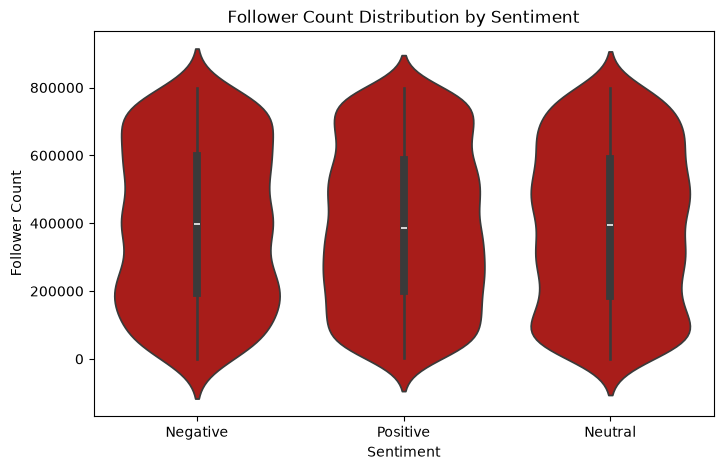

In [240]:
# Chart 9: Violin Plot – Followers by Sentiment
plt.figure(figsize=(8, 5))
sns.violinplot(
    data=df,
    x='sentiment',
    y='follower_count',color='#bf0603')
plt.xlabel('Sentiment')
plt.ylabel('Follower Count')
plt.title('Follower Count Distribution by Sentiment')
plt.show()

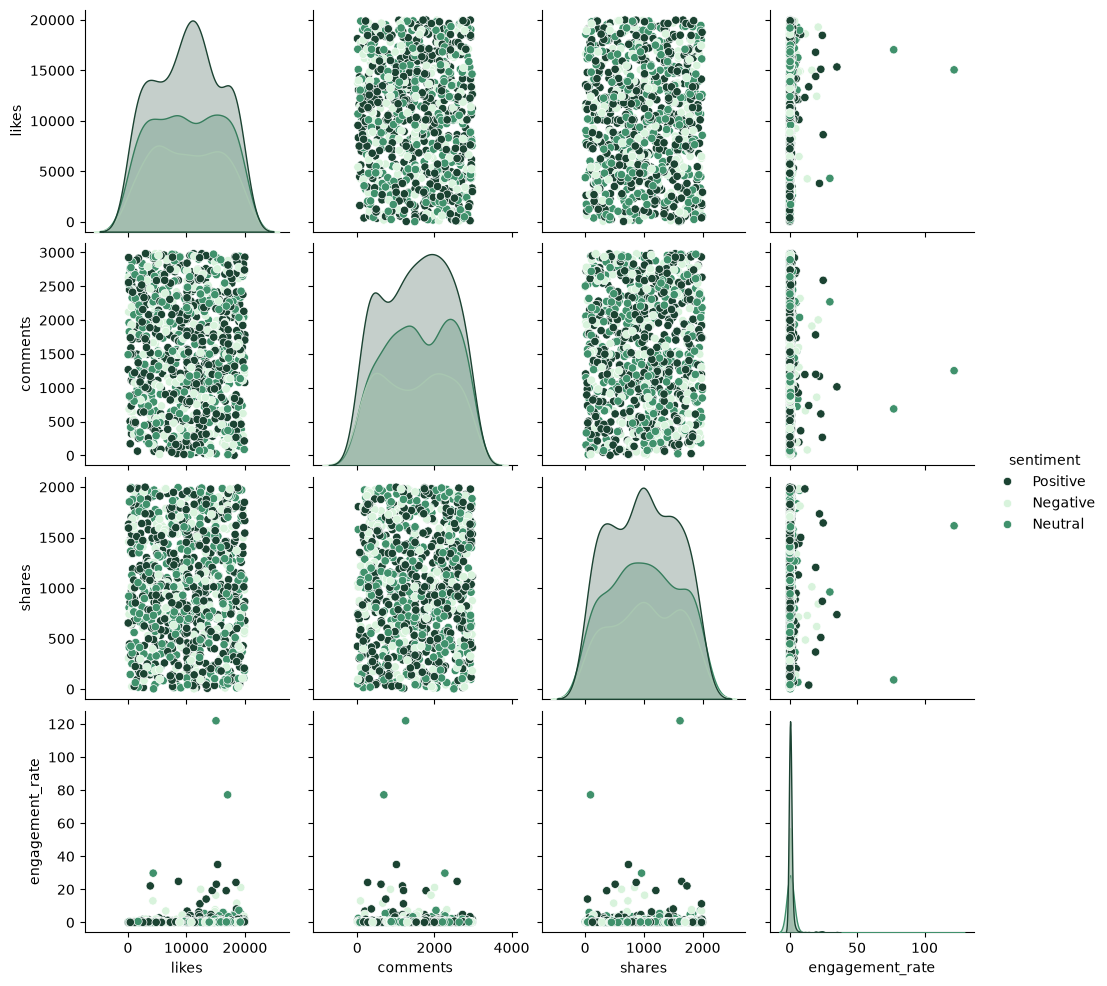

In [241]:
# Chart 10: Pair Plot – Relationships Between Numerical Features
pair_cols = ['likes', 'comments', 'shares', 'engagement_rate']
pair_data = df[pair_cols + ['sentiment']].sample(
    n=min(1000, len(df)),
    random_state=42
)
sns.pairplot(
    pair_data,
    hue='sentiment',
    palette={
        'Positive': '#1b4332',
        'Neutral': '#40916c',
        'Negative': '#d8f3dc'
    }
)
plt.show()

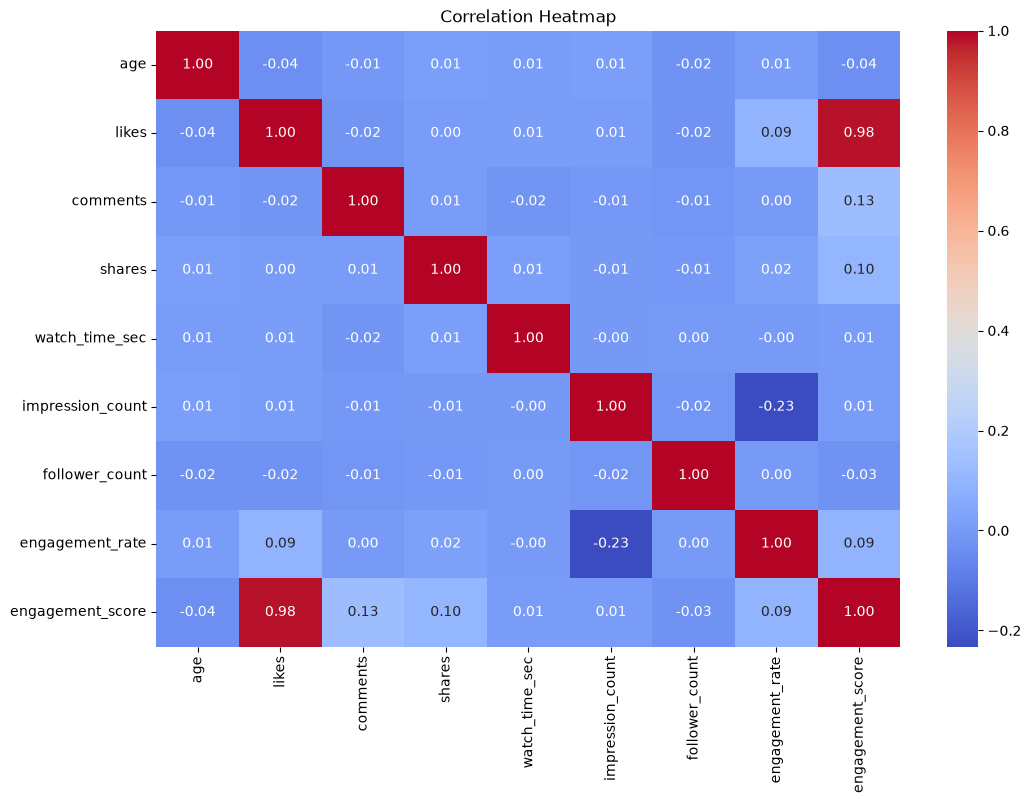

In [242]:
# Chart 11: Correlation Heatmap
corr_cols = [
    'age',
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'impression_count',
    'follower_count',
    'engagement_rate',
    'engagement_score'
]
plt.figure(figsize=(12, 8))
sns.heatmap(
    df[corr_cols].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Heatmap')

plt.show()

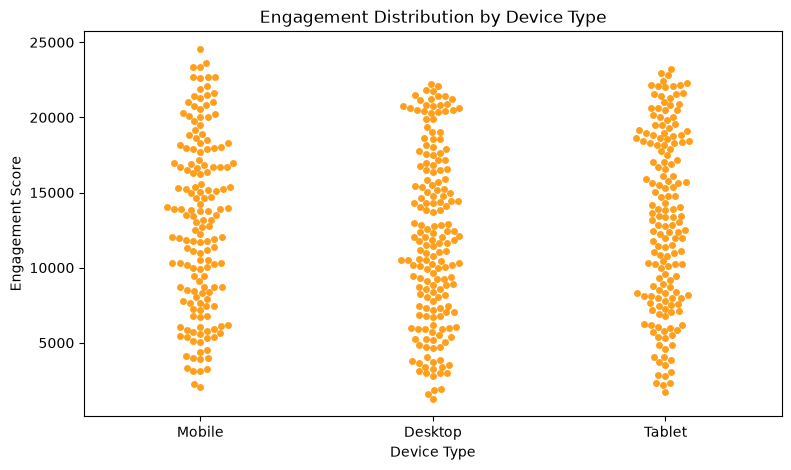

In [243]:
# Chart 12: Swarm Plot – Engagement by Device Type
swarm_data = df.sample(
    n=min(500, len(df)),
    random_state=42
)
plt.figure(figsize=(9, 5))
sns.swarmplot(
    data=swarm_data,
    x='device_type',
    y='engagement_score',
    color='#ff9f1c'
)
plt.xlabel('Device Type')
plt.ylabel('Engagement Score')
plt.title('Engagement Distribution by Device Type')
plt.show()

**PLOTLY**

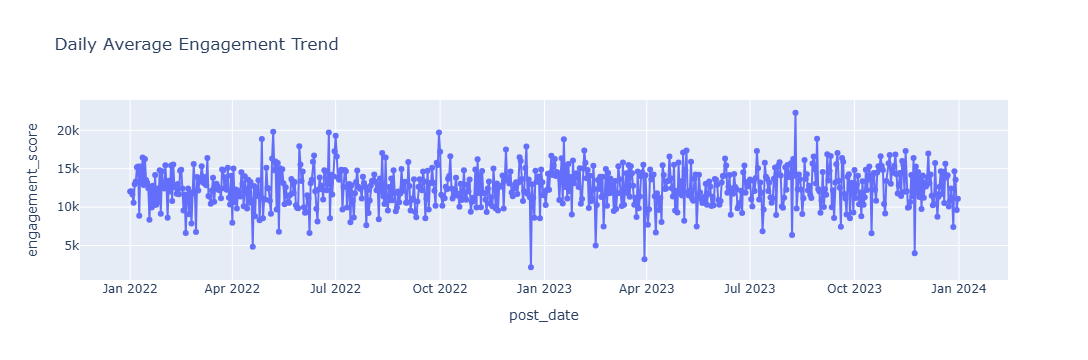

In [244]:
# Chart 13: Interactive Line Chart – Daily Engagement
daily_df = (
    df.groupby('post_date', as_index=False)['engagement_score']
    .mean()
)
fig = px.line(
    daily_df,
    x='post_date',
    y='engagement_score',
    title='Daily Average Engagement Trend',
    markers=True
)
fig.show()

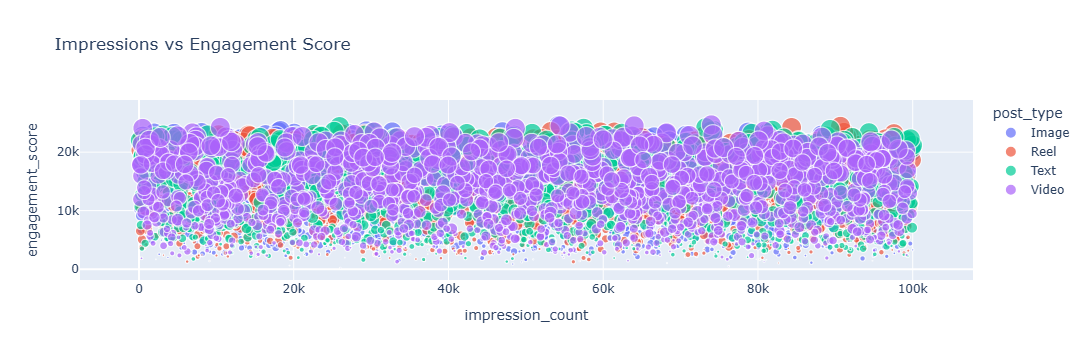

In [245]:
#Chart 14: Interactive Bubble Chart – Impressions vs Engagement 
fig = px.scatter(
    df,
    x='impression_count',
    y='engagement_score',
    size='likes',
    color='post_type',
    hover_data=['post_id'],
    title='Impressions vs Engagement Score',
    size_max=20
)

fig.show()

<div style="
    background: #EAF3FC;
    padding: 14px 20px;
    border-left: 5px solid #2878B8;
    border-radius: 5px;
">
    <h2 style="color: #174B75; margin: 0;">
        08 | Final Insights and Business Recommendations
    </h2>
</div>

In [246]:
# Which Post Type Has the Highest Engagement?
result = df.groupby('post_type')['engagement_score'].mean()

print(result.sort_values(ascending=False))

print("\nBest Post Type:", result.idxmax())

post_type
Video    12664.580408
Image    12649.377706
Text     12613.228112
Reel     12524.014030
Name: engagement_score, dtype: float64

Best Post Type: Video


In [247]:
# Best Performing Post Category
result = df.groupby('post_category')['engagement_rate'].mean()

print(result.sort_values(ascending=False))
print("\nBest Category:", result.idxmax())

post_category
Food         1.358628
Tech         1.160475
Lifestyle    1.091019
Music        0.888803
Fitness      0.865628
Education    0.844222
Fashion      0.807109
Travel       0.702223
Name: engagement_rate, dtype: float64

Best Category: Food


In [248]:
# Countries With Highest Average Engagement Rate
result = df.groupby('country')['engagement_rate'].mean()

print(result.sort_values(ascending=False))
print("\nTop Country:", result.idxmax())

country
Brazil       1.540704
Australia    1.324339
France       1.146402
Uae          1.112352
Canada       0.916659
Uk           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
Usa          0.576580
Name: engagement_rate, dtype: float64

Top Country: Brazil


In [249]:
# Relationship Between Age and Engagement
result = df.groupby('age')['engagement_rate'].mean()

print(result.sort_values(ascending=False).head())
print("\nAge With Highest Average Engagement:", result.idxmax())

age
24    2.897327
55    2.599106
51    2.397295
48    1.675878
50    1.552627
Name: engagement_rate, dtype: float64

Age With Highest Average Engagement: 24


In [250]:
# Verified vs Unverified Users
result = df.groupby('is_verified')['engagement_rate'].mean()
print(result)

is_verified
False    0.954744
True     1.054250
Name: engagement_rate, dtype: float64


In [253]:
# Best Time of Day for Impressions
result = df.groupby('post_day')['impression_count'].mean()

print(result.sort_values(ascending=False))
print("\nBest Posting Hour:", result.idxmax())

post_day
Tuesday      51308.589849
Saturday     50945.228095
Sunday       50345.670782
Monday       50013.224928
Wednesday    49857.990000
Friday       49430.537827
Thursday     48119.289398
Name: impression_count, dtype: float64

Best Posting Hour: Tuesday


In [254]:
# Device Impact on Watch Time
result = df.groupby('device_type')['watch_time_sec'].mean()

print(result.sort_values(ascending=False))
print("\nBest Device:", result.idxmax())

device_type
Mobile     4087.830760
Tablet     3979.736429
Desktop    3974.792521
Name: watch_time_sec, dtype: float64

Best Device: Mobile


In [255]:
#Sentiment Performance
result = df.groupby('sentiment')['engagement_score'].mean()

print(result.sort_values(ascending=False))

sentiment
Negative    12731.483333
Positive    12665.784322
Neutral     12448.149312
Name: engagement_score, dtype: float64


In [256]:
# Negative and Neutral Sentiment Analysis
result = df.groupby('sentiment')[['likes', 'comments', 'shares']].mean()

print(result.loc[['Negative', 'Neutral']].round(2))

              likes  comments   shares
sentiment                             
Negative   10208.08   1516.09  1007.31
Neutral     9923.18   1528.40   996.57


In [257]:
# Top 5 Posts by Engagement
top_posts = df.nlargest(5, 'engagement_score')

print(top_posts[['post_id', 'post_type', 'post_category',
                 'engagement_score', 'engagement_rate']])

      post_id post_type post_category  engagement_score  engagement_rate
41     147547     Video          Food             24680         0.333631
1632   641620     Image          Food             24583         0.453452
3814   943395     Video          Food             24509         0.382929
3223   182790     Video          Food             24486         0.449986
2998   462928      Reel         Music             24423         0.269397


<div style="
    background: #EAF3FC;
    padding: 14px 20px;
    border-left: 5px solid #2878B8;
    border-radius: 5px;
">
    <h2 style="color: #174B75; margin: 0;">
        PROJECT COMPLETED
    </h2>
</div>